In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

## Block Matching

In [ ]:
def compute_sad(window1, window2):
    return np.sum(np.abs(window1 - window2))

def compute_ssd(window1, window2):
    return np.sum((window1 - window2) ** 2)

In [ ]:
def block_matching(Il, Ir, window_size, cost_function):
    h, w = Il.shape
    disparity_map = np.zeros_like(Il, dtype=np.float32)

    half_window = window_size // 2

    for y in range(half_window, h - half_window):
        for x in range(half_window, w - half_window):
            min_cost = float('inf')
            best_disparity = 0
            window_left = Il[y - half_window:y + half_window + 1, x - half_window:x + half_window + 1]

            for d in range(half_window, x):
                if x - d - half_window < 0:
                    continue

                window_right = Ir[y - half_window:y + half_window + 1, x - d - half_window:x - d + half_window + 1]
                cost = cost_function(window_left, window_right)
                if cost < min_cost:
                    min_cost = cost
                    best_disparity = d

            disparity_map[y, x] = best_disparity

    return disparity_map

In [ ]:
def visualize_disparity(disparity_maps, type):
    plt.figure(figsize=(20, 5))

    for i in range(len(disparity_maps)):
        plt.subplot(1, 3, i+1)
        plt.imshow(disparity_maps[i], cmap='gray')
        plt.title(f'Disparity Map {type}, W= {1 + (4 * i)}')
        plt.colorbar(label='Disparity')

    plt.tight_layout()
    plt.show()


In [ ]:
# Load test images (grayscale)
Il = cv2.imread("assets/l1.png", cv2.IMREAD_GRAYSCALE)
Ir = cv2.imread("assets/r1.png", cv2.IMREAD_GRAYSCALE)

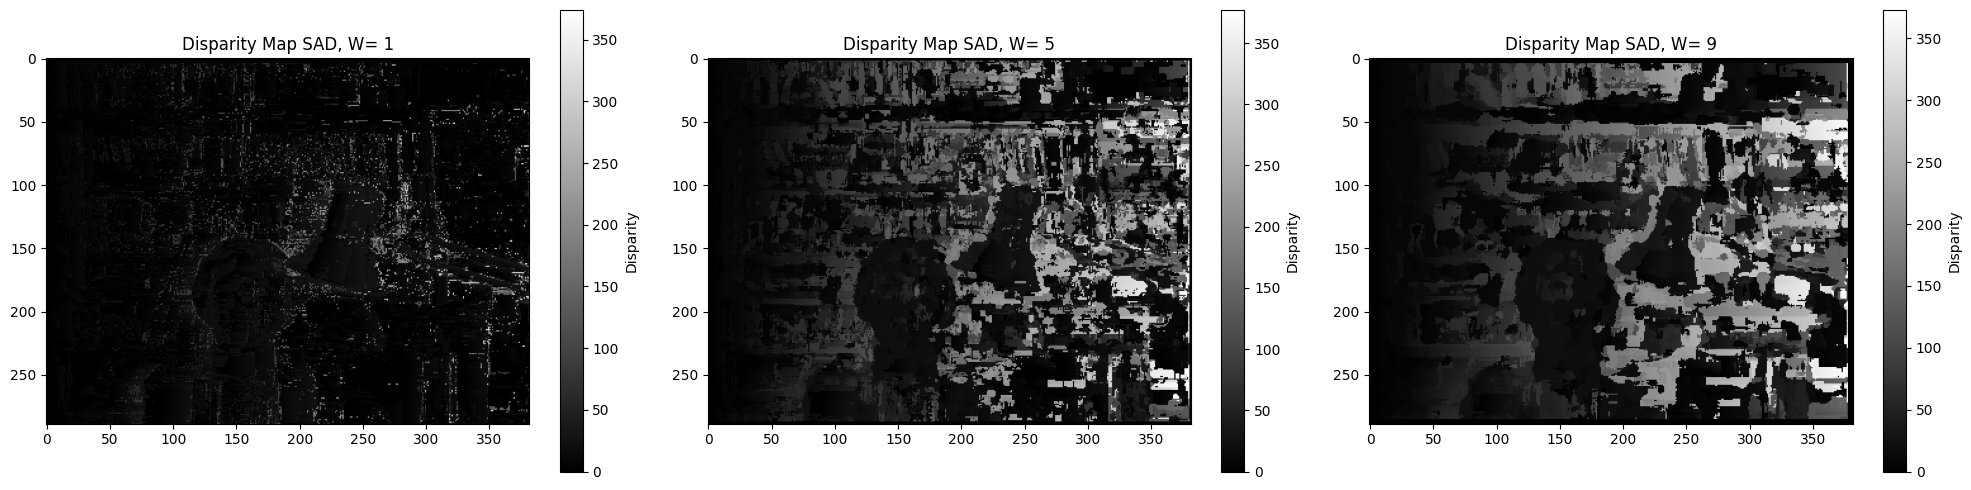

In [ ]:
# Block Matching (SAD)
sad_dps=[]
for window_size in [1, 5, 9]:
    disparity_sad = block_matching(Il, Ir, window_size, compute_sad)
    sad_dps.append(disparity_sad)
visualize_disparity(sad_dps, "SAD")

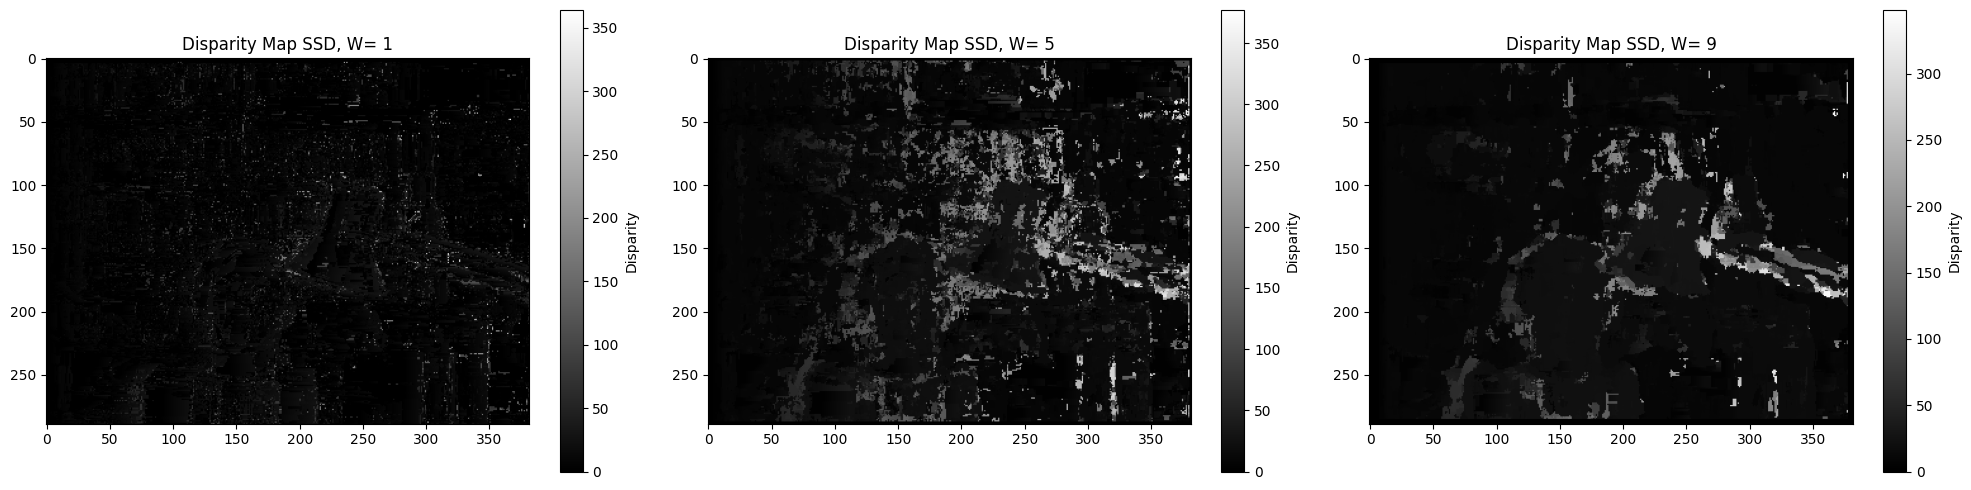

In [ ]:
# Block Matching (SSD)
ssd_dps=[]
for window_size in [1, 5, 9]:
    disparity_ssd = block_matching(Il, Ir, window_size, compute_ssd)
    ssd_dps.append(disparity_ssd)
visualize_disparity(ssd_dps, "SSD")

In [ ]:
# Load test images (grayscale)
Il = cv2.imread("assets/l2.png", cv2.IMREAD_GRAYSCALE)
Ir = cv2.imread("assets/r2.png", cv2.IMREAD_GRAYSCALE)

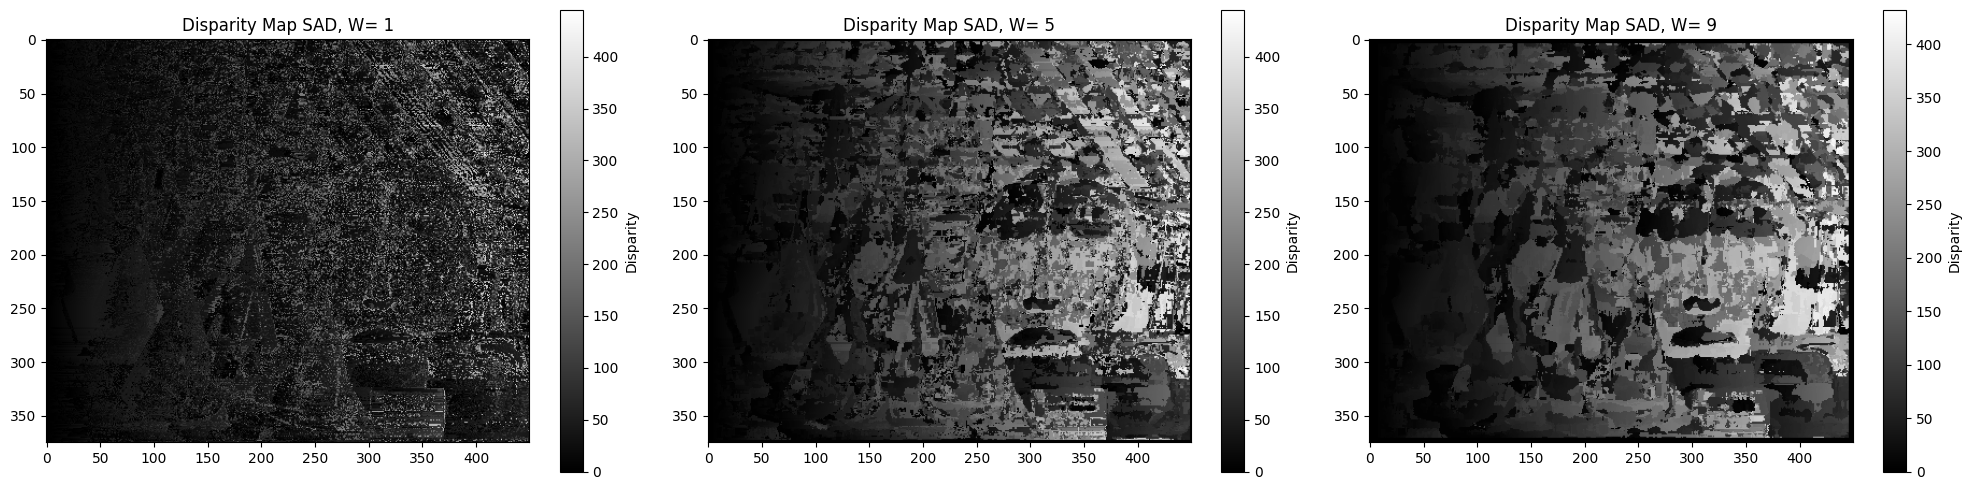

In [ ]:
# Block Matching (SAD)
sad_dps=[]
for window_size in [1, 5, 9]:
    disparity_sad = block_matching(Il, Ir, window_size, compute_sad)
    sad_dps.append(disparity_sad)
visualize_disparity(sad_dps, "SAD")

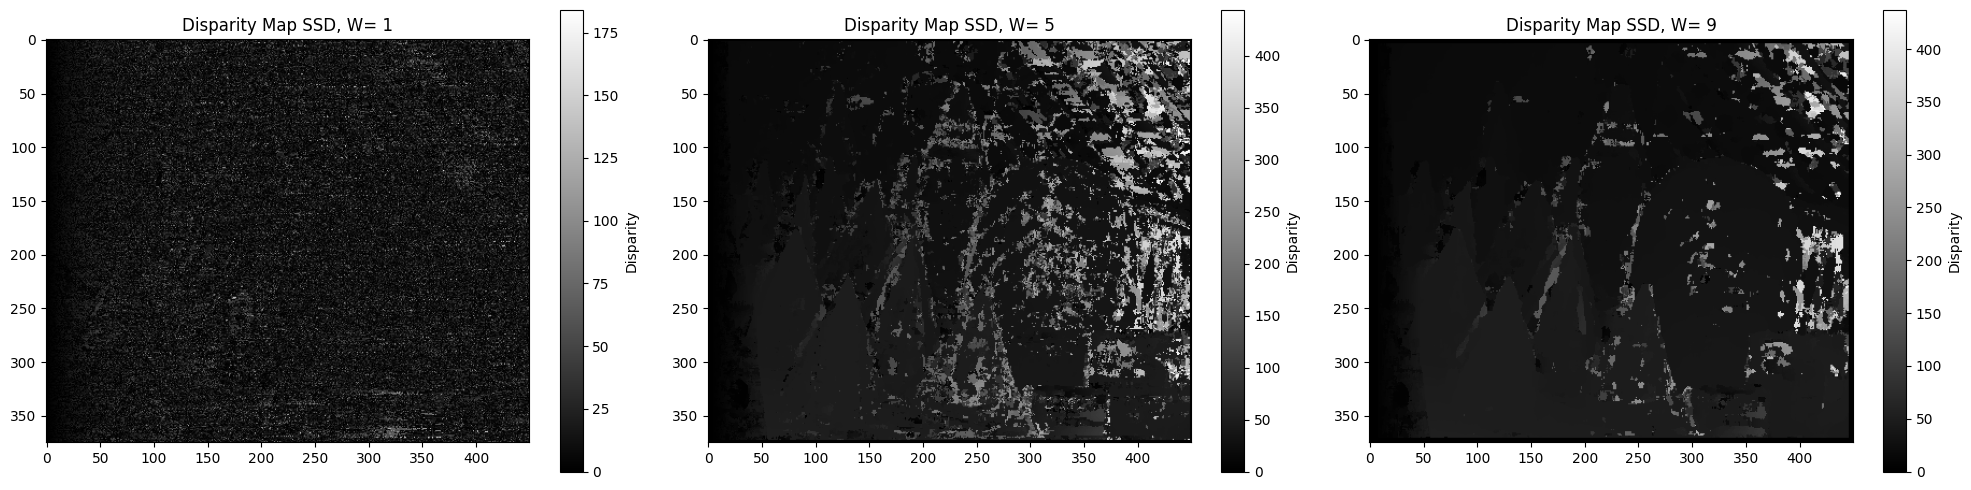

In [ ]:
# Block Matching (SSD)
ssd_dps=[]
for window_size in [1, 5, 9]:
    disparity_ssd = block_matching(Il, Ir, window_size, compute_ssd)
    ssd_dps.append(disparity_ssd)
visualize_disparity(ssd_dps, "SSD")

In [ ]:
# Load test images (grayscale)
Il = cv2.imread("assets/l3.png", cv2.IMREAD_GRAYSCALE)
Ir = cv2.imread("assets/r3.png", cv2.IMREAD_GRAYSCALE)

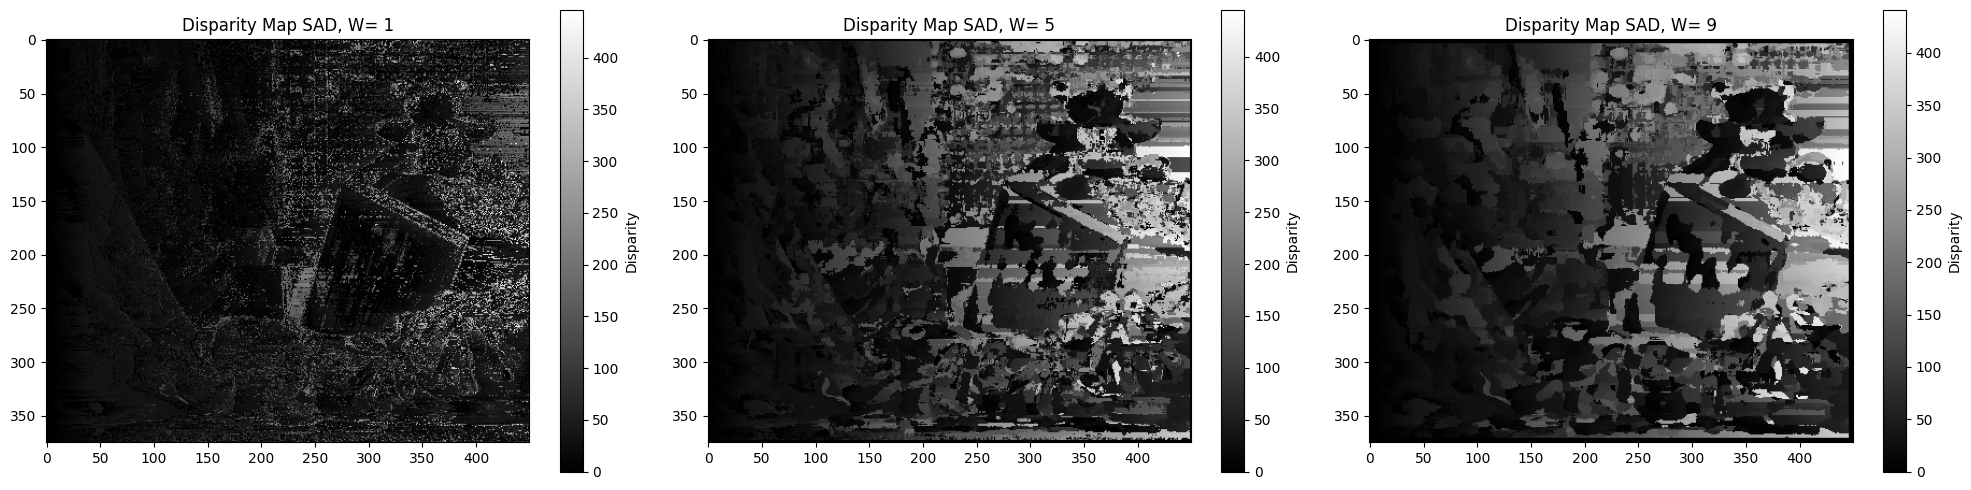

In [ ]:
# Block Matching (SAD)
sad_dps=[]
for window_size in [1, 5, 9]:
    disparity_sad = block_matching(Il, Ir, window_size, compute_sad)
    sad_dps.append(disparity_sad)
visualize_disparity(sad_dps, "SAD")

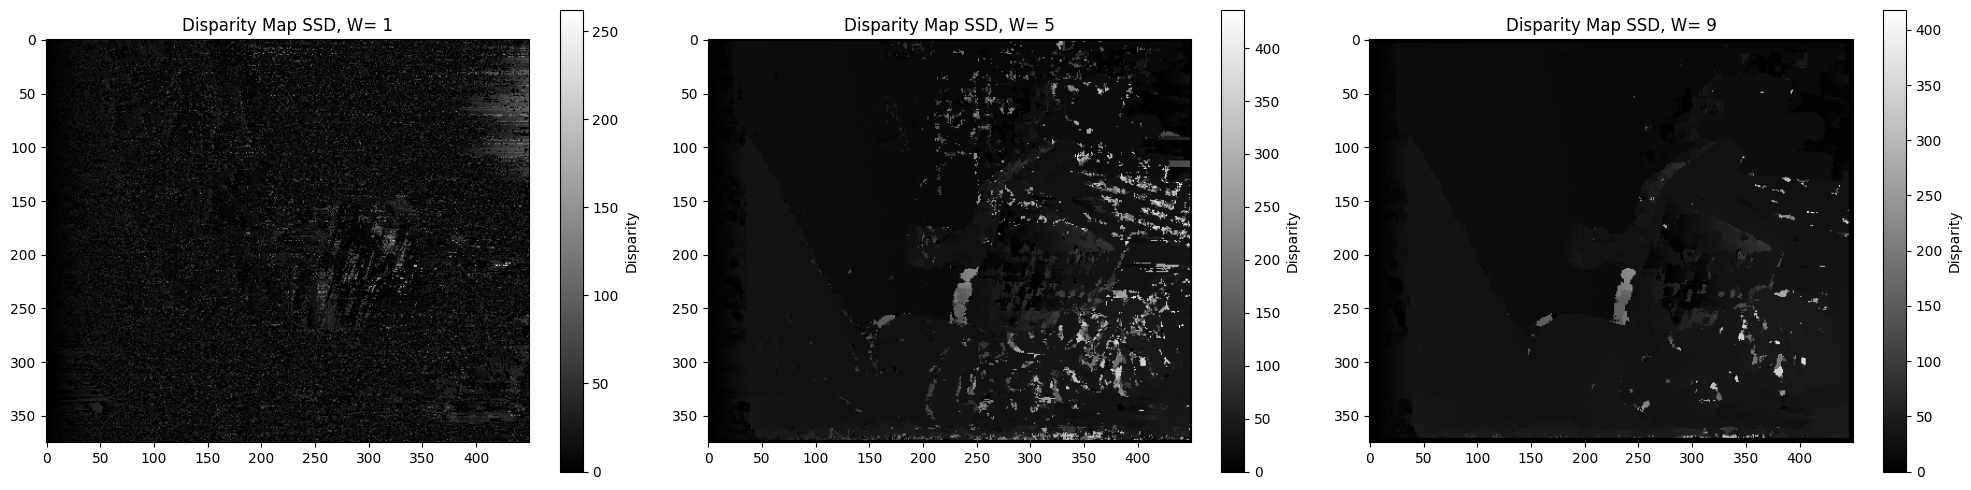

In [ ]:
# Block Matching (SSD)
ssd_dps=[]
for window_size in [1, 5, 9]:
    disparity_ssd = block_matching(Il, Ir, window_size, compute_ssd)
    ssd_dps.append(disparity_ssd)
visualize_disparity(ssd_dps, "SSD")

## Dynamic Programming

In [ ]:
def dynamic_programming(Il, Ir, sigma=2, c0=1):
    Il = Il.astype(np.float32)
    Ir = Ir.astype(np.float32) #Transform to float to avoid overflow

    h, w = Il.shape
    disparity_left = np.zeros_like(Il, dtype=np.float32)
    disparity_right = np.zeros_like(Ir, dtype=np.float32)

    for row in range(h):
        left = Il[row]
        right = Ir[row]

        D = np.zeros((w, w))
        D[0,0]= ((left[0] - right[0]) ** 2) / (sigma ** 2)

        for i in range(1, w):
            D[i, 0] = D[i - 1, 0] + c0
            D[0, i] = D[0, i - 1] + c0

        for i in range(1, w):
            for j in range(1, w):
                dij = ((left[i] - right[j]) ** 2) / (sigma ** 2)
                D[i, j] = min(
                    D[i - 1, j - 1] + dij,  # Match
                    D[i - 1, j] + c0,       # Skip in `Il`
                    D[i, j - 1] + c0        # Skip in `Ir`
                )

        # Backtracking to compute disparity
        i, j = w-1, w-1
        while i > 0 and j > 0:
            cur_min= min(D[i-1, j-1], D[i-1, j], D[i, j-1])
            if cur_min == D[i-1, j-1]:
                # Match pixels
                disparity_left[row, i-1] = abs(i - j)
                disparity_right[row, j-1] = abs(i - j)
                i -= 1
                j -= 1
            elif cur_min == D[i-1, j]:
                  # Skip a pixel in Il
                  i -= 1
            else:
                # Skip a pixel in Ir
                  j -= 1

    return disparity_left, disparity_right

In [ ]:
def visualize_disparity_maps(left_disp, right_disp):
    """
    Visualize disparity maps
    """

    plt.figure(figsize=(15, 5))

    plt.subplot(1,2,1)
    plt.title('Left Disparity Map')
    plt.imshow(left_disp, cmap='gray')
    plt.colorbar(label='Disparity')

    plt.subplot(1,2,2)
    plt.title('Right Disparity Map')
    plt.imshow(right_disp, cmap='gray')
    plt.colorbar(label='Disparity')

    plt.tight_layout()
    plt.show()

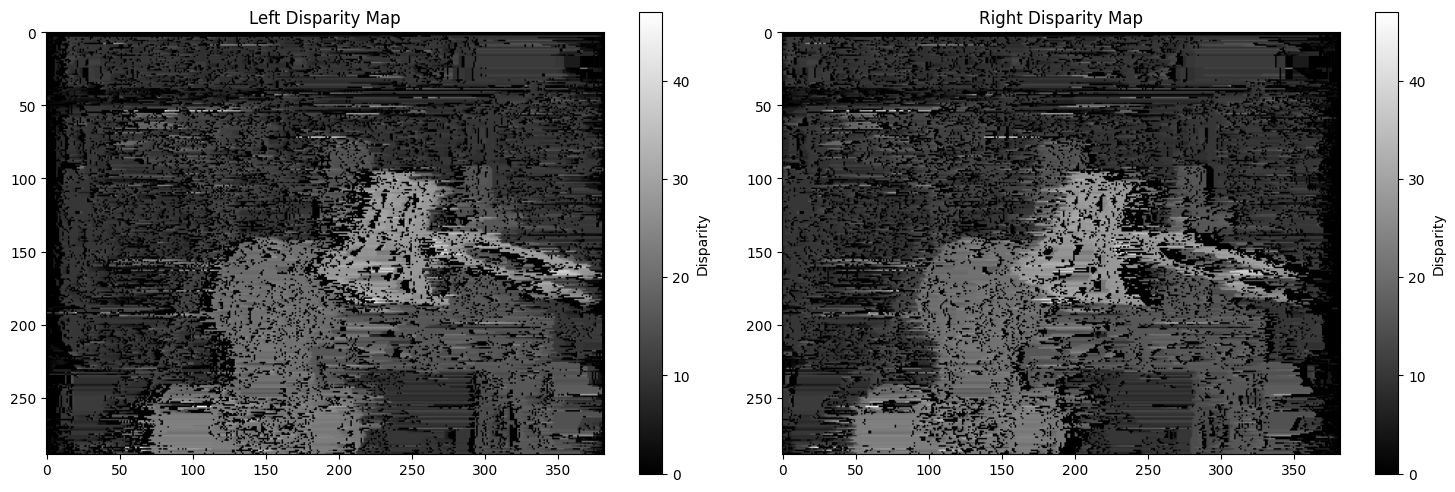

In [ ]:
# Load test images (grayscale)
Il = cv2.imread("assets/l1.png", cv2.IMREAD_GRAYSCALE)
Ir = cv2.imread("assets/r1.png", cv2.IMREAD_GRAYSCALE)
# Dynamic Programming
disparity_dp = dynamic_programming(Il, Ir)
visualize_disparity_maps(disparity_dp[0], disparity_dp[1])

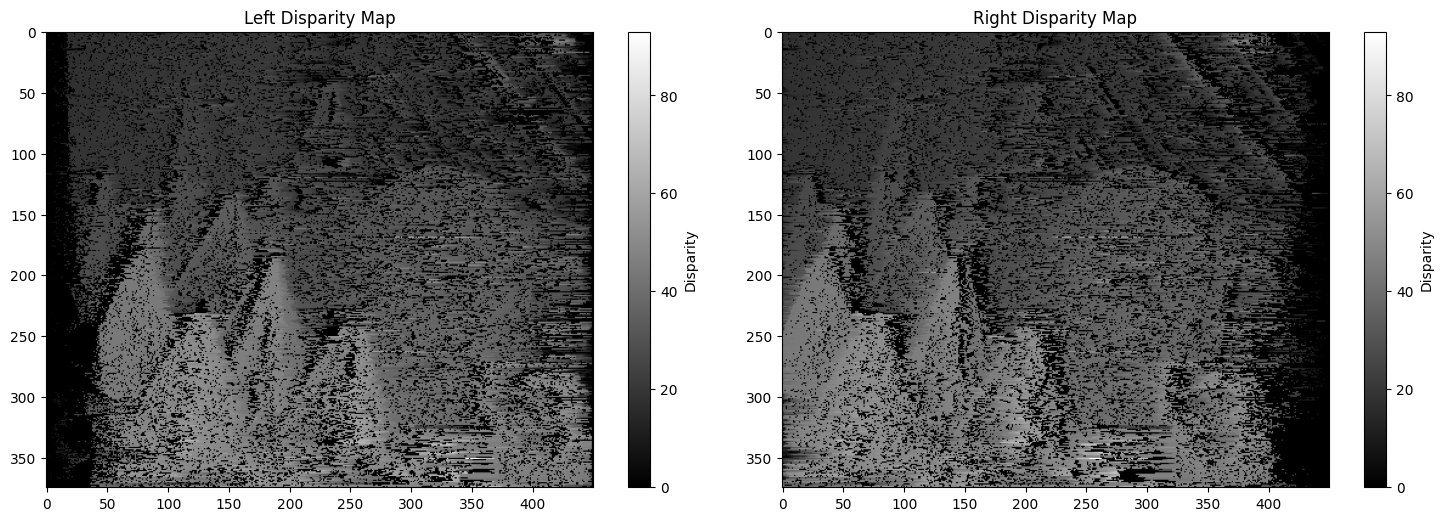

In [ ]:
# Load test images (grayscale)
Il = cv2.imread("assets/l2.png", cv2.IMREAD_GRAYSCALE)
Ir = cv2.imread("assets/r2.png", cv2.IMREAD_GRAYSCALE)
# Dynamic Programming
disparity_dp = dynamic_programming(Il, Ir)
visualize_disparity_maps(disparity_dp[0], disparity_dp[1])

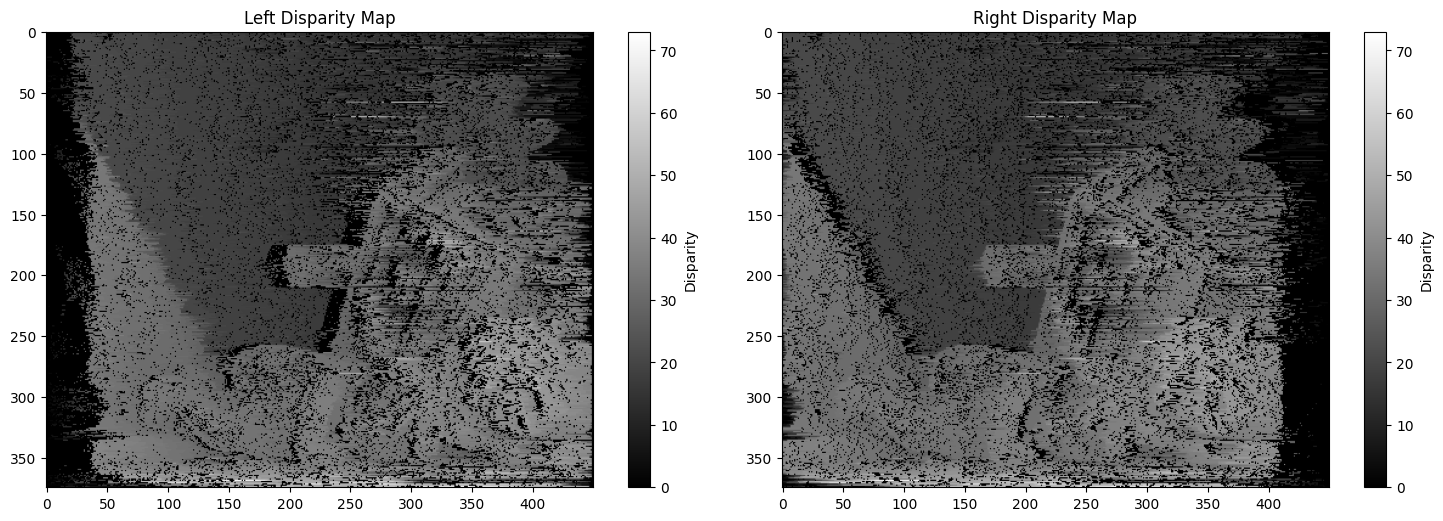

In [ ]:
# Load test images (grayscale)
Il = cv2.imread("assets/l3.png", cv2.IMREAD_GRAYSCALE)
Ir = cv2.imread("assets/r3.png", cv2.IMREAD_GRAYSCALE)
# Dynamic Programming
disparity_dp = dynamic_programming(Il, Ir)
visualize_disparity_maps(disparity_dp[0], disparity_dp[1])

<ipython-input-21-c153998dd66a>:17: RuntimeWarning: overflow encountered in scalar subtract
  if D[i, j] == D[i-1, j-1] + ((Il[i, j] - Ir[i, j]) ** 2) / (sigma ** 2):


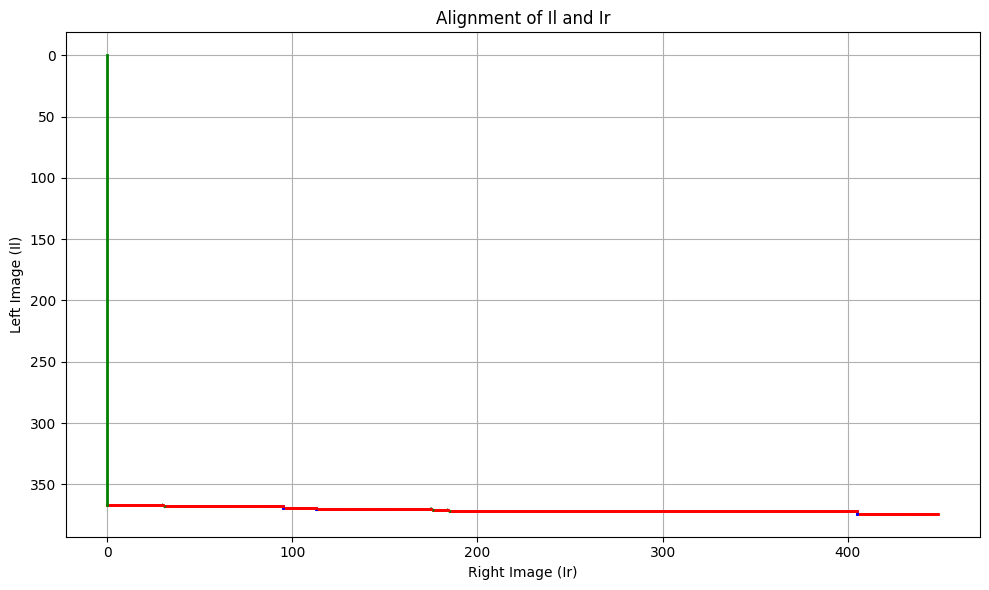

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

def plot_alignment(D, Il, Ir, sigma=2, c0=1):
    h, w = Il.shape

    # Start at the bottom-right corner of the disparity map
    i, j = h - 1, w - 1

    # Plot the matching process
    plt.figure(figsize=(10, 6))

    # Go through the matrix D from bottom-right to top-left to track the best path
    while i > 0 and j > 0:
        # Match condition: pixels in both images match
        if D[i, j] == D[i-1, j-1] + ((Il[i, j] - Ir[i, j]) ** 2) / (sigma ** 2):
            plt.plot([j, j-1], [i, i-1], 'g-', lw=2)  # Diagonal (match)
            i -= 1
            j -= 1
        # Skip a pixel in Il
        elif D[i, j] == D[i-1, j] + c0:
            plt.plot([j, j], [i, i-1], 'b-', lw=2)  # Vertical (skip in Ir)
            i -= 1
        # Skip a pixel in Ir
        else:
            plt.plot([j, j-1], [i, i], 'r-', lw=2)  # Horizontal (skip in Il)
            j -= 1

    # Connect the remaining points to (0, 0)
    plt.plot([j, 0], [i, 0], 'g-', lw=2)  # Diagonal from (i, j) to (0, 0)

    plt.title("Alignment of Il and Ir")
    plt.xlabel("Right Image (Ir)")
    plt.ylabel("Left Image (Il)")
    plt.gca().invert_yaxis()  # Invert y-axis for correct plotting direction
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Load test images (grayscale)
Il = cv2.imread("assets/l3.png", cv2.IMREAD_GRAYSCALE)
Ir = cv2.imread("assets/r3.png", cv2.IMREAD_GRAYSCALE)

# You should already have the disparity matrix D computed from dynamic programming.
# For the sake of demonstration, let's assume you have disparity values `disparity_left`, `disparity_right`
# Here I am assuming a hypothetical function dynamic_programming() that computes the disparity matrix.

disparity_left, disparity_right = dynamic_programming(Il, Ir)

# Visualize the alignment
plot_alignment(disparity_left, Il, Ir)


<ipython-input-12-69502d3f833b>:8: RuntimeWarning: overflow encountered in scalar subtract
  return ((Il[i] - Ir[j]) ** 2) / (sigma ** 2)


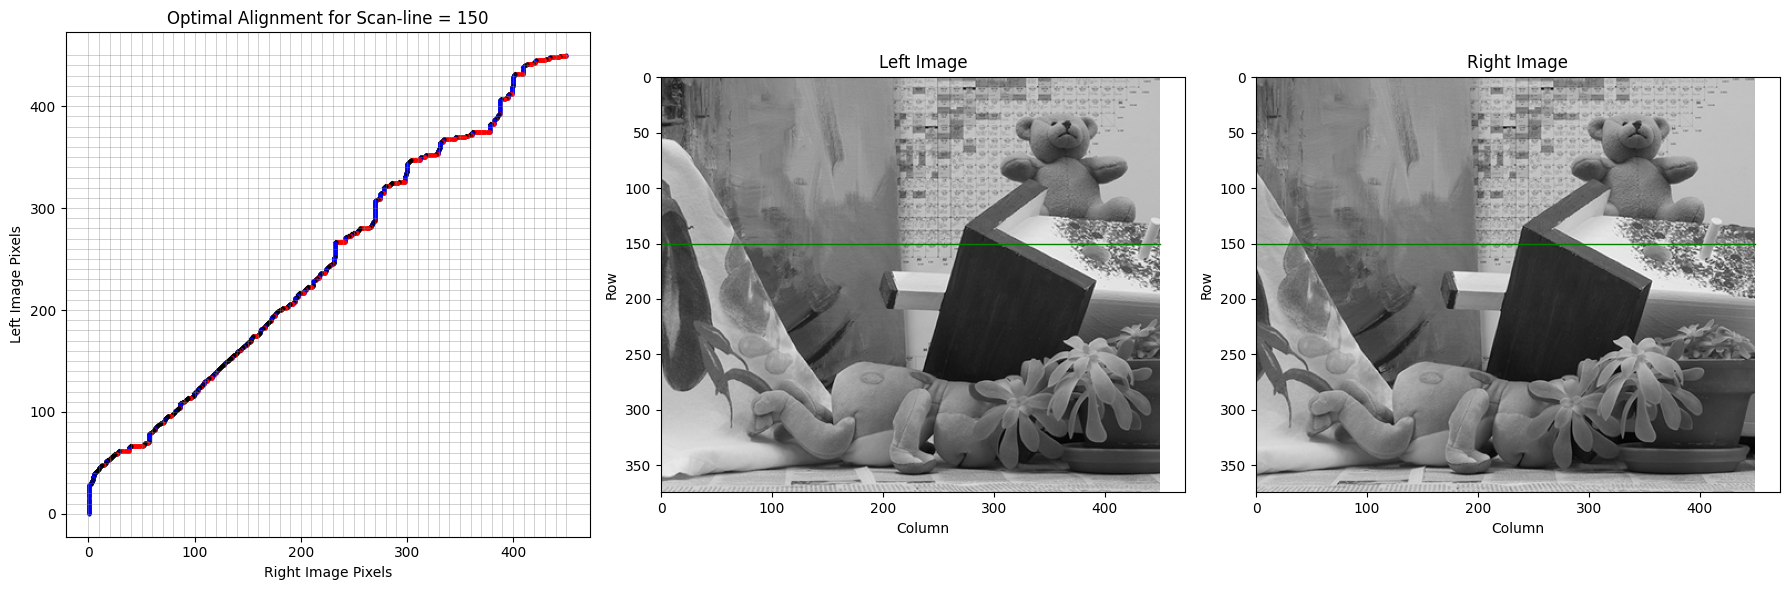

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

def compute_cost(Il, Ir, i, j, sigma):
    """Compute the cost for aligning two pixels."""
    return ((Il[i] - Ir[j]) ** 2) / (sigma ** 2)

def plot_alignment(Il, Ir, h, ax, sigma=2, c0=1):
    """
    Plots the optimal alignment for a single scan-line using Dynamic Programming.
    Vertical: skip in right image (blue).
    Horizontal: skip in left image (red).
    Diagonal: match (black).
    """
    N = len(Il) + 1

    # Initialize cost matrix
    D = np.zeros((N, N))
    for i in range(N):
        D[i, 0] = i * c0
        D[0, i] = i * c0

    # Fill the cost matrix
    for i in range(1, N):
        for j in range(1, N):
            dij = compute_cost(Il, Ir, i - 1, j - 1, sigma)
            D[i, j] = min(
                D[i - 1, j - 1] + dij,  # Match
                D[i - 1, j] + c0,      # Skip in left
                D[i, j - 1] + c0       # Skip in right
            )

    # Backtrack for alignment
    i, j = N - 1, N - 1
    while i > 0 and j > 0:
        if D[i, j] == D[i - 1, j - 1] + compute_cost(Il, Ir, i - 1, j - 1, sigma):
            # Diagonal line (match)
            ax.plot([j - 1, j], [i - 1, i], color='black', linewidth=2, marker='o', markersize=2)
            i -= 1
            j -= 1
        elif D[i, j] == D[i - 1, j] + c0:
            # Vertical line (skip in right image)
            ax.plot([j, j], [i - 1, i], color='blue', linewidth=0.5, marker='o', markersize=2)
            i -= 1
        else:
            # Horizontal line (skip in left image)
            ax.plot([j - 1, j], [i, i], color='red', linewidth=0.5, marker='o', markersize=2)
            j -= 1

    # Add grid and labels
    for k in range(0, N, 10):
        ax.axhline(k, color='grey', linewidth=0.5, alpha=0.5)
        ax.axvline(k, color='grey', linewidth=0.5, alpha=0.5)
    ax.set_title(f"Optimal Alignment for Scan-line = {h}")
    ax.set_xlabel("Right Image Pixels")
    ax.set_ylabel("Left Image Pixels")

def main():
    # Directory setup
    results_dir = 'results/dp'
    os.makedirs(results_dir, exist_ok=True)

    # Input image file paths
    left_images = ['l3.png']
    right_images = ['r3.png']
    scanline_height = 150

    for image_index in range(len(left_images)):
        fig, axs = plt.subplots(1, 3, figsize=(18, 6))

        # Load images
        img_left = cv2.imread(left_images[image_index], cv2.IMREAD_GRAYSCALE)
        img_right = cv2.imread(right_images[image_index], cv2.IMREAD_GRAYSCALE)

        # Plot alignment
        plot_alignment(img_left[scanline_height], img_right[scanline_height], scanline_height, axs[0])

        # Left image with scan-line
        axs[1].imshow(img_left, cmap='gray')
        axs[1].plot([0, img_left.shape[1]], [scanline_height, scanline_height], color='green', linewidth=1)
        axs[1].set_title("Left Image")
        axs[1].set_xlabel("Column")
        axs[1].set_ylabel("Row")

        # Right image with scan-line
        axs[2].imshow(img_right, cmap='gray')
        axs[2].plot([0, img_right.shape[1]], [scanline_height, scanline_height], color='green', linewidth=1)
        axs[2].set_title("Right Image")
        axs[2].set_xlabel("Column")
        axs[2].set_ylabel("Row")

        plt.tight_layout()
        plt.show()

        # Save figure
        fig.savefig(os.path.join(results_dir, f'scanline_{image_index + 1}.png'), dpi=fig.dpi)

# Run the main function
main()


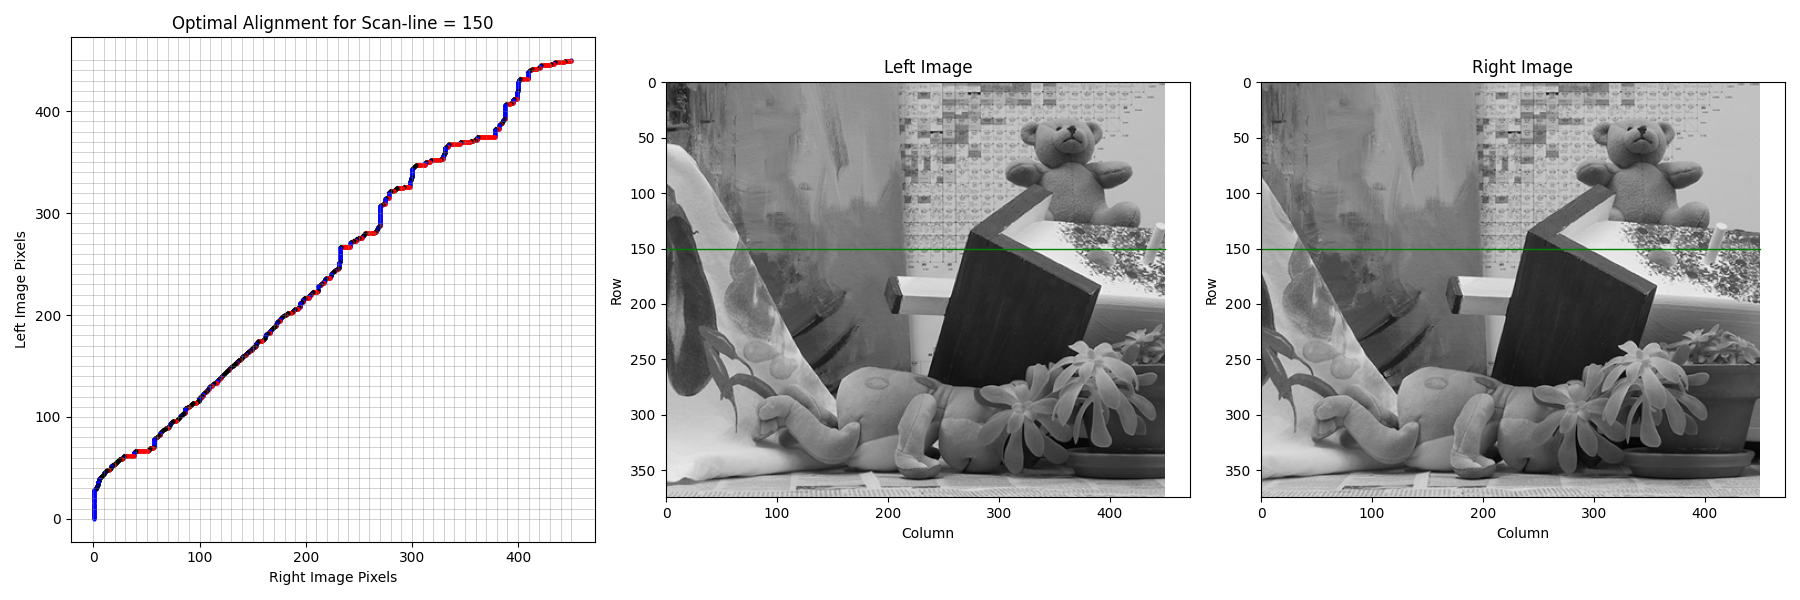

In [ ]:
from IPython.display import Image
Image('outputs/scanline_1.png')